In [1]:
!pip install -q git+https://github.com/abhibarnwal707/PaperTrail.git
import os
from kaggle_secrets import UserSecretsClient
os.environ["DAGSHUB_USER_TOKEN"] = UserSecretsClient().get_secret("DAGSHUB_TOKEN")
import dagshub, mlflow
dagshub.init(repo_owner="abhibarnwal707", repo_name="papertrail", mlflow=True)


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 512.4 kB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 1.2 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.0/274.0 kB 2.6 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 51.5 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 81.3 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 52.1 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.4/73.4 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.5/231.5 kB 5.3 MB/s eta 0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━

Accessing as abhibarnwal707

Initialized MLflow to track repo "abhibarnwal707/papertrail"

Repository abhibarnwal707/papertrail initialized!

In [2]:
import papertrail.features as f
print(hasattr(f, "add_out_count_24h"))   # should print True


True


In [3]:
# load the processed data from the Kaggle Dataset
import glob
import numpy as np
import polars as pl

path = glob.glob("/kaggle/input/**/transactions.parquet", recursive=True)[0]
df = pl.read_parquet(path).sort(["ts", "txn_id"])
print(path, df.shape)

/kaggle/input/datasets/abhibarnwal707/papertrail-processed/transactions.parquet (5078345, 16)


In [5]:
# History feature (needed by one rule), then the fixed split from Phase 2
from papertrail.features import add_out_count_24h
from papertrail.split import assert_valid_split, split_summary, temporal_split

df = add_out_count_24h(df)          # looks strictly backwards, so it is safe to compute before splitting
train, val, test = temporal_split(df)
summary = split_summary(df)
pl.Config.set_tbl_cols(-1)
print(summary)
assert_valid_split(summary)

shape: (4, 6)
┌──────────────┬─────────┬───────────┬──────────┬─────────────────────┬─────────────────────┐
│ split        ┆ rows    ┆ positives ┆ pos_rate ┆ start               ┆ end                 │
│ ---          ┆ ---     ┆ ---       ┆ ---      ┆ ---                 ┆ ---                 │
│ str          ┆ i64     ┆ i64       ┆ f64      ┆ datetime[μs]        ┆ datetime[μs]        │
╞══════════════╪═════════╪═══════════╪══════════╪═════════════════════╪═════════════════════╡
│ train        ┆ 3248921 ┆ 2530      ┆ 0.000779 ┆ 2022-09-01 00:00:00 ┆ 2022-09-06 23:59:00 │
│ val          ┆ 965524  ┆ 1036      ┆ 0.001073 ┆ 2022-09-07 00:00:00 ┆ 2022-09-08 23:59:00 │
│ test         ┆ 862792  ┆ 956       ┆ 0.001108 ┆ 2022-09-09 00:00:00 ┆ 2022-09-10 23:59:00 │
│ dropped_tail ┆ 1108    ┆ 655       ┆ 0.591155 ┆ 2022-09-11 00:05:00 ┆ 2022-09-18 16:18:00 │
└──────────────┴─────────┴───────────┴──────────┴─────────────────────┴─────────────────────┘


In [6]:
# Sanity check that the 3K-30K amount band covers the training laundering amounts
pos_amt = train.filter(pl.col("label") == 1)["amt_paid"]
print({q: round(pos_amt.quantile(q), 2) for q in (0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95)})


{0.05: 171.82, 0.1: 488.77, 0.25: 2224.18, 0.5: 7032.52, 0.75: 18666.46, 0.9: 137549.9, 0.95: 782356.91}


In [7]:
# Shared evaluation helper (protocol: threshold on validation, test scored once per model)
from papertrail.metrics import best_f1_threshold, evaluate

y_val = val["label"].to_numpy()
y_test = test["label"].to_numpy()
ach_test = (test["pay_format"] == "ACH").to_numpy()


def run_eval(p_val, p_test):
    thr = best_f1_threshold(y_val, p_val)
    res = {"threshold": float(thr)}
    for k, v in evaluate(y_val, p_val, thr).items():
        res[f"val_{k}"] = v
    for k, v in evaluate(y_test, p_test, thr).items():
        res[f"test_{k}"] = v
    # secondary view from the protocol: ACH-only transactions (86.6% of all positives)
    for k, v in evaluate(y_test[ach_test], p_test[ach_test], thr).items():
        res[f"test_ach_{k}"] = v
    return res

In [8]:
# Rule-based baseline
from papertrail.rules import fit_rule_params, rule_flags, rule_score

rule_params = fit_rule_params(train)   # thresholds come from the training split only
print(rule_params)

# each rule on its own, on validation (for insight only, nothing is tuned on it)
flags = rule_flags(val, rule_params)
for c in ["r_high_amount", "r_ach_band", "r_burst"]:
    fired = flags[c].to_numpy()
    tp = int((fired & (y_val == 1)).sum())
    print(f"{c:15s} flagged={int(fired.sum()):8d}  precision={tp / max(int(fired.sum()), 1):.4f}  "
          f"recall={tp / int(y_val.sum()):.3f}")

s_val, s_test = rule_score(val, rule_params), rule_score(test, rule_params)
with mlflow.start_run(run_name="rules_baseline"):
    mlflow.log_params({f"rule_{k}": v for k, v in rule_params.items()})
    rules_res = run_eval(s_val, s_test)
    mlflow.log_metrics(rules_res)
print({k: round(v, 4) for k, v in rules_res.items() if k.startswith("test_") and "ach" not in k})

{'amt_high': 15952734.67, 'burst': 19445.0}
r_high_amount   flagged=    7020  precision=0.0019  recall=0.013
r_ach_band      flagged=   26685  precision=0.0196  recall=0.505
r_burst         flagged=       0  precision=0.0000  recall=0.000
🏃 View run rules_baseline at: https://dagshub.com/abhibarnwal707/papertrail.mlflow/#/experiments/0/runs/71733532cf764f8fbe88e15b38ead0ff
🧪 View experiment at: https://dagshub.com/abhibarnwal707/papertrail.mlflow/#/experiments/0
{'test_pr_auc': 0.008, 'test_f1': 0.0303, 'test_recall_at_1pct_fpr': 0.0115, 'test_precision_at_1000': 0.0}


(3248921, 16) scale_pos_weight = 1283.2
[0]	validation_0-aucpr:0.00987
[50]	validation_0-aucpr:0.03956
[100]	validation_0-aucpr:0.04710
[134]	validation_0-aucpr:0.04720


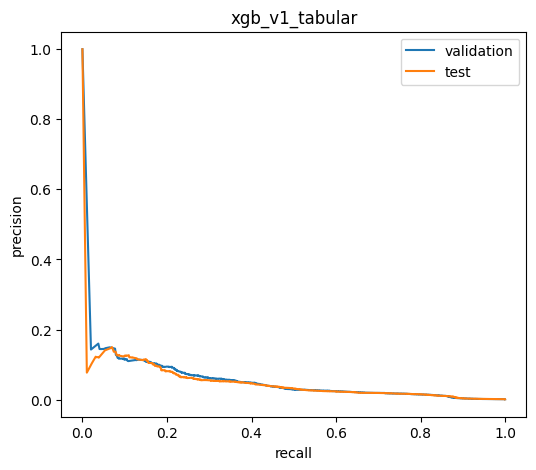

🏃 View run xgb_v1_tabular at: https://dagshub.com/abhibarnwal707/papertrail.mlflow/#/experiments/0/runs/0b37096b8c8841c5baf235092e4bf23e
🧪 View experiment at: https://dagshub.com/abhibarnwal707/papertrail.mlflow/#/experiments/0
shape: (16, 2)
┌───────────────────┬──────────┐
│ feature           ┆ gain     │
│ ---               ┆ ---      │
│ str               ┆ f64      │
╞═══════════════════╪══════════╡
│ is_ach            ┆ 0.457119 │
│ fmt_ACH           ┆ 0.346159 │
│ is_self_transfer  ┆ 0.026787 │
│ is_same_bank      ┆ 0.026128 │
│ is_cross_currency ┆ 0.023351 │
│ …                 ┆ …        │
│ fmt_Bitcoin       ┆ 0.009344 │
│ fmt_Reinvestment  ┆ 0.00842  │
│ cur_code          ┆ 0.006561 │
│ hour              ┆ 0.005658 │
│ is_round_amount   ┆ 0.003866 │
└───────────────────┴──────────┘


In [9]:
# XGBoost v1 on tabular features
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import precision_recall_curve

from papertrail.features import build_features, fit_categories

cats = fit_categories(train)


def to_matrix(part):
    return build_features(part, cats).cast(pl.Float32).to_numpy()


X_train, X_val, X_test = to_matrix(train), to_matrix(val), to_matrix(test)
y_train = train["label"].to_numpy()
feat_names = build_features(train.head(5), cats).columns
spw = float((y_train == 0).sum() / y_train.sum())
print(X_train.shape, "scale_pos_weight =", round(spw, 1))

xgb_params = dict(
    tree_method="hist", n_estimators=1000, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw,
    eval_metric="aucpr", early_stopping_rounds=50, n_jobs=-1, random_state=0,
)
model = xgb.XGBClassifier(**xgb_params)
model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=50)   # early stopping on validation PR-AUC

p_val = model.predict_proba(X_val)[:, 1]
p_test = model.predict_proba(X_test)[:, 1]

with mlflow.start_run(run_name="xgb_v1_tabular"):
    mlflow.log_params({k: v for k, v in xgb_params.items() if k != "eval_metric"})
    mlflow.log_param("n_features", len(feat_names))
    mlflow.log_param("best_iteration", int(model.best_iteration))
    xgb_res = run_eval(p_val, p_test)
    mlflow.log_metrics(xgb_res)

    # PR curves (validation and test) as an image
    fig, ax = plt.subplots(figsize=(6, 5))
    for name, y, p in (("validation", y_val, p_val), ("test", y_test, p_test)):
        pr, rc, _ = precision_recall_curve(y, p)
        ax.plot(rc, pr, label=name)
    ax.set_xlabel("recall")
    ax.set_ylabel("precision")
    ax.set_title("xgb_v1_tabular")
    ax.legend()
    mlflow.log_figure(fig, "pr_curve.png")
    plt.show()

    # model + feature importance as artifacts (registry comes later, in Step 5.4)
    model.save_model("/kaggle/working/xgb_v1.json")
    mlflow.log_artifact("/kaggle/working/xgb_v1.json")
    imp = pl.DataFrame({"feature": feat_names, "gain": model.feature_importances_.tolist()}).sort(
        "gain", descending=True)
    imp.write_csv("/kaggle/working/xgb_v1_importance.csv")
    mlflow.log_artifact("/kaggle/working/xgb_v1_importance.csv")
print(imp)


In [10]:
# Comparison table (test split) and files to download
rows = []
for name, res in (("Rules", rules_res), ("XGB tabular", xgb_res)):
    rows.append({
        "Model": name,
        "PR-AUC": res["test_pr_auc"],
        "F1 (minority)": res["test_f1"],
        "Recall@1%FPR": res["test_recall_at_1pct_fpr"],
        "Precision@1000": res["test_precision_at_1000"],
        "ACH-only PR-AUC": res["test_ach_pr_auc"],
        "ACH-only F1": res["test_ach_f1"],
    })
table = pl.DataFrame(rows)
print(f"test positives: {int(y_test.sum())} of {len(y_test)} (base rate {y_test.mean():.4%})")
print(table)

import json
table.write_csv("/kaggle/working/baseline_table.csv")
with open("/kaggle/working/baseline_metrics.json", "w") as fh:
    json.dump({"rules_baseline": rules_res, "xgb_v1_tabular": xgb_res, "rule_params": rule_params,
               "scale_pos_weight": spw, "best_iteration": int(model.best_iteration)}, fh, indent=2)

print("commit message idea:",
      f"XGB tabular baseline: PR-AUC {xgb_res['test_pr_auc']:.3f}, F1 {xgb_res['test_f1']:.2f}")
# download baseline_table.csv, baseline_metrics.json and xgb_v1_importance.csv from the Output tab


test positives: 956 of 862792 (base rate 0.1108%)
shape: (2, 7)
┌─────────────┬──────────┬────────────────┬──────────────┬────────────────┬──────────┬─────────────┐
│ Model       ┆ PR-AUC   ┆ F1 (minority)  ┆ Recall@1%FPR ┆ Precision@1000 ┆ ACH-only ┆ ACH-only F1 │
│ ---         ┆ ---      ┆ ---            ┆ ---          ┆ ---            ┆ PR-AUC   ┆ ---         │
│ str         ┆ f64      ┆ f64            ┆ f64          ┆ f64            ┆ ---      ┆ f64         │
│             ┆          ┆                ┆              ┆                ┆ f64      ┆             │
╞═════════════╪══════════╪════════════════╪══════════════╪════════════════╪══════════╪═════════════╡
│ Rules       ┆ 0.007986 ┆ 0.030262       ┆ 0.011506     ┆ 0.0            ┆ 0.019062 ┆ 0.049308    │
│ XGB tabular ┆ 0.046082 ┆ 0.116461       ┆ 0.408996     ┆ 0.116          ┆ 0.0524   ┆ 0.121274    │
└─────────────┴──────────┴────────────────┴──────────────┴────────────────┴──────────┴─────────────┘
commit message idea: XGB ta